# Lab 03: How a model asks for a tool

## Goal

Give a model a tool and run the round trip yourself: describe a Python function as a JSON schema, read the request
the model sends back, run the function in your own code and return its result. The moment that teaches it comes in
Part F. We send back a false result (2 invoices, where the database has 7) and the model repeats it in
every run (5 of 5), although asked from memory it usually says 7. The model never runs anything: it believes whatever our
code returns.

## What you will learn

- how to describe a Python function to the model as a strict JSON schema (`strict`, `additionalProperties: false`,
  every field required);
- how to read a tool call: its `id`, the function name, and `arguments`, which is a JSON string;
- how to run the function in our own code and send the result back in a `tool` message with the same id;
- how to handle a reply that asks for several tools at once;
- what the API answers when a tool message has the wrong id or is missing;
- why the tool result is the thing to protect: the model repeats what it is given.

## Setup

The first cell is the same in every lab: it finds the repository folder, reads the model and prices from
`models.env`, and takes the key from `.env` without printing it (lab 00 explains it line by line). This lab adds
`json`, `re` and `sqlite3`, all three from Python's standard library.

In [1]:
from pathlib import Path
import json
import os
import re
import sqlite3
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


`EFFORT` is the reasoning effort set in `models.env`, and it is `none` there on purpose: on Chat Completions this
model calls function tools only with effort `none` (with `low` the API returns a 400 that points to the Responses
API; lab 01 shows that error). Every call in this lab passes `reasoning_effort=EFFORT or omit`: `omit` is the
`openai` package's marker for "leave this parameter out of the request", so a model without reasoning (an empty
`REASONING_EFFORT`, where `EFFORT` is `None`) gets no `reasoning_effort` at all instead of an invalid `null`.

## Part A: Look up Helena's facts with plain Python functions

Our running question is one a support rep asks every day: *How many invoices does Helena Holý have, what do they
add up to, and who is her support rep?* Before any model is involved, we write the three lookups that answer it and
call them ourselves. These are the functions the model will later ask for, and nothing about them changes when they
become tools.

The shop's data is `data/chinook.db`, a SQLite file. We open it **read-only**: `mode=ro` in the connection string
makes every write fail, which matters once a model chooses the arguments. `uri=True` tells `sqlite3` to read that
string as a URI, and `check_same_thread=False` lets a framework call our functions from another thread in later
labs (it changes nothing here).

In [2]:
# The shop database, opened read-only
DB = ROOT / "data" / "chinook.db"
con = sqlite3.connect(f"file:{DB}?mode=ro", uri=True, check_same_thread=False)
print("opened:", DB.relative_to(ROOT))

opened: data/chinook.db


First the raw object: Helena's row in the `customers` table, as SQLite returns it.

In [3]:
row = con.execute(
    "SELECT CustomerId, FirstName, LastName, Country, SupportRepId FROM customers WHERE LastName = 'Holý'"
).fetchone()
print(row)

(6, 'Helena', 'Holý', 'Czech Republic', 5)


One row comes back as a Python tuple, in the order of the `SELECT`:

- **6**: `CustomerId`, the key the other tables use for her;
- **'Helena', 'Holý'**: first and last name, in two columns;
- **'Czech Republic'**: her country;
- **5**: `SupportRepId`. This is not a name: it is the `EmployeeId` of her rep in the `employees` table.

So the three lookups depend on each other: the name gives the id, and the id gives the invoices and the rep.

`find_customer` takes a full name and returns every exact match. The `?` in the SQL is a placeholder: `sqlite3`
passes `name` as a value, never as part of the SQL text. That matters here, because from Part D on the name comes
from the model.

In [4]:
def find_customer(name):
    """Find customers whose first and last name match `name` exactly."""
    rows = con.execute(
        "SELECT CustomerId, FirstName || ' ' || LastName, Country FROM customers "
        "WHERE FirstName || ' ' || LastName = ?",
        (name,),
    ).fetchall()
    return [{"customer_id": r[0], "name": r[1], "country": r[2]} for r in rows]


print(find_customer("Helena Holý"))

[{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'}]


A list with one dict. It is a list because a name can match nobody (an empty list) or several people (the shop has
two customers named Mark), and the caller has to see all of them. Three pieces of the code carry this:

- `||` joins strings in SQL, so we compare the name against first name, a space and last name;
- `(name,)` is a tuple with one item: the values for the `?` placeholders, in order;
- the list comprehension turns each row tuple into a dict with named keys, so whoever reads the result does not
  need to know the column order.

The other two functions take the id. `get_invoices` counts her invoices and adds up their totals; `round(..., 2)`
keeps the sum to dollars and cents.

In [5]:
def get_invoices(customer_id):
    """Count a customer's invoices and add up their totals."""
    count, total = con.execute(
        "SELECT COUNT(*), SUM(Total) FROM invoices WHERE CustomerId = ?", (customer_id,)
    ).fetchone()
    return {"customer_id": customer_id, "invoice_count": count, "total": round(total or 0, 2)}


print(get_invoices(6))

{'customer_id': 6, 'invoice_count': 7, 'total': 49.62}


`get_support_rep` follows `SupportRepId` into the `employees` table with a `JOIN`: the customer row's
`SupportRepId` must equal the employee row's `EmployeeId`.

In [6]:
def get_support_rep(customer_id):
    """Name the support rep assigned to a customer."""
    found = con.execute(
        "SELECT e.FirstName || ' ' || e.LastName FROM customers c "
        "JOIN employees e ON e.EmployeeId = c.SupportRepId WHERE c.CustomerId = ?",
        (customer_id,),
    ).fetchone()
    return {"customer_id": customer_id, "support_rep": found[0] if found else None}


print(get_support_rep(6))

{'customer_id': 6, 'support_rep': 'Steve Johnson'}


**Checkpoint A.** These are the facts every later answer is checked against:

| Fact | Value | From |
|---|---|---|
| customer id | 6 | `find_customer` |
| country | Czech Republic | `find_customer` |
| invoices | 7 | `get_invoices` |
| total | $49.62 | `get_invoices` |
| support rep | Steve Johnson | `get_support_rep` |

Each function returns plain Python (a list, a dict). No model was called, and none was needed. The question for the
rest of the lab is how a model asks our code to run them.

## Part B: Describe a function to the model as a strict JSON schema

The model cannot see our Python. It sees only what we send in the request, so to let it ask for `find_customer` we
have to describe the function there. First, a smaller question that one lookup answers, asked with no description at
all.

`OpenAI()` builds the client; it reads `OPENAI_API_KEY` from the environment, where the setup cell put it. `SYSTEM`
is a one-line system prompt we keep for the whole lab.

In [7]:
from openai import OpenAI, omit

client = OpenAI()

SYSTEM = "You are a support assistant for the Chinook music shop."
QUESTION = "Which country is Helena Holý from, and what is her customer id?"

We send the question three times with no tools and print each reply's `finish_reason` and text. Look at the
customer id.

In [8]:
messages = [
    {"role": "system", "content": SYSTEM},
    {"role": "user", "content": QUESTION},
]

for run in range(3):
    response = client.chat.completions.create(
        model=MODEL,
        messages=messages,
        reasoning_effort=EFFORT or omit,
        max_completion_tokens=300,
    )
    print(run + 1, response.choices[0].finish_reason, "|", response.choices[0].message.content)

1 stop | Helena Holý is from the Czech Republic, and her customer ID is 16.


2 stop | Helena Holý is from the Czech Republic, and her customer ID is 5.


3 stop | Helena Holý is from the Czech Republic, and her customer ID is 5.


`finish_reason` is `stop` in each run: the model finished with text. The country is right every time, but the customer id is 16, then 5, then 5, and the database says 6 (Part A). Each guess comes in the same confident sentence a right answer would. The model has seen the
Chinook sample database in its training data, so it answers fluently, but nothing was looked up.

Now the description. A tool on Chat Completions is a dict with `"type": "function"` and a `function` object inside
it. We write it and print it before sending it.

In [9]:
FIND_CUSTOMER_TOOL = {
    "type": "function",
    "function": {
        "name": "find_customer",
        "description": "Find a Chinook customer by full name. Returns a list of matches, each with its customer_id.",
        "parameters": {
            "type": "object",
            "properties": {
                "name": {"type": "string", "description": "The customer's first and last name"},
            },
            "required": ["name"],
            "additionalProperties": False,
        },
        "strict": True,
    },
}

print(json.dumps(FIND_CUSTOMER_TOOL, indent=2))

{
  "type": "function",
  "function": {
    "name": "find_customer",
    "description": "Find a Chinook customer by full name. Returns a list of matches, each with its customer_id.",
    "parameters": {
      "type": "object",
      "properties": {
        "name": {
          "type": "string",
          "description": "The customer's first and last name"
        }
      },
      "required": [
        "name"
      ],
      "additionalProperties": false
    },
    "strict": true
  }
}


Field by field:

| Field | What it holds | Who reads it |
|---|---|---|
| `type` | `"function"`, the kind of tool | the API |
| `function.name` | `find_customer`: the name the model sends back when it wants this tool | our code, to pick the Python function |
| `function.description` | what the tool does and what it returns | the model, to decide whether to ask for it |
| `function.parameters` | a JSON Schema for the arguments: an object with one string field, `name` | the model, to write the arguments; the API, to check them |
| `required` | every field in `properties` | strict mode needs all of them |
| `additionalProperties: false` | no fields other than `name` | strict mode needs it |
| `function.strict` | `true`: the arguments must match the schema exactly | the API |

`json.dumps` printed Python's `False` and `True` as JSON's `false` and `true`; the API receives this JSON form.

**Important:** the dict is a description, not a link to Python. Creating it runs nothing, and the API never sees the
code of `find_customer`.

**Why strict?** Without `strict`, Chat Completions treats the schema as a best effort: the arguments usually match,
but nothing guarantees it. With `"strict": true` the API holds the model's arguments to the schema (the mechanism
behind structured outputs), and OpenAI recommends always turning it on. It costs two rules: `additionalProperties`
must be `false`, and every field must be listed in `required`. A field that may be empty is typed
`["string", "null"]` instead of being left out of `required`. A schema that breaks a rule is refused with a 400 that
names it (see the troubleshooting table at the end).

**Predict:** with this tool in the request, will the reply be text or a tool call?

In [10]:
response = client.chat.completions.create(
    model=MODEL,
    messages=messages,
    tools=[FIND_CUSTOMER_TOOL],
    reasoning_effort=EFFORT or omit,
    max_completion_tokens=300,
)
reply = response.choices[0].message

print("finish_reason:", response.choices[0].finish_reason)
print("content:      ", reply.content)
print("tool_calls:   ", reply.tool_calls)

finish_reason: tool_calls
content:       None
tool_calls:    [ChatCompletionMessageFunctionToolCall(id='call_dxOGTlIXESOyoHa6KbUC3nRk', function=Function(arguments='{"name":"Helena Holý"}', name='find_customer'), type='function')]


Read the three lines:

- `finish_reason` is `tool_calls`, not `stop`: the model ended its turn to ask for a tool;
- `content` is `None`: there is no answer text at all;
- `tool_calls` is a list with one `ChatCompletionMessageFunctionToolCall`, an object of the `openai` package.

Nothing ran. `find_customer` printed nothing and the database was not read; the model can reach neither. Its whole
contribution is the object in `tool_calls`. **The model never calls a tool: it asks, and our code decides.**

**Checkpoint B.** Without tools: `finish_reason` `stop` and a guessed customer id. With the schema:
`finish_reason` `tool_calls`, `content` `None`, one tool call.

## Part C: Read the tool request the model sends back

The request is an object with a few fields, and our code is about to act on them, so we read them one at a time.

In [11]:
call = reply.tool_calls[0]

print("id:                ", call.id)
print("type:              ", call.type)
print("function.name:     ", call.function.name)
print("function.arguments:", call.function.arguments)
print("type of arguments: ", type(call.function.arguments))

id:                 call_dxOGTlIXESOyoHa6KbUC3nRk
type:               function
function.name:      find_customer
function.arguments: {"name":"Helena Holý"}
type of arguments:  <class 'str'>


- **`id`**: a string the API made for this one request (it starts with `call_`). We send it back with the result,
  so the model can tell which request the result answers.
- **`type`**: `function`, the only kind of tool this lab uses.
- **`function.name`**: `find_customer`, one of the names we described. It is only a string.
- **`function.arguments`**: `{"name":"Helena Holý"}`, and its type is `str`. It looks like a dict, but it is text:
  JSON that the model wrote. To use it, we parse it.

`json.loads` turns a JSON string into Python objects; a JSON object becomes a `dict`.

In [12]:
args = json.loads(call.function.arguments)
print(args)
print(type(args))

{'name': 'Helena Holý'}
<class 'dict'>


Now `args["name"]` is `'Helena Holý'`. Strict mode guaranteed the shape (one field, `name`, a string). It does not
guarantee the value is a real customer: the function's result still decides that.

**Nothing forces us to run it.** This is where our code is in charge. We could refuse a name we do not know, check
the arguments, ask a person first, or only log the request. Every safety measure in an agent sits here, between the
request and the run.

**Checkpoint C.** One tool call: `find_customer` with `{"name": "Helena Holý"}`; `arguments` is a `str` before
`json.loads` and a `dict` after.

## Part D: Run the function and send its result back with the call's id

We decide to run it. `find_customer(**args)` unpacks the dict into keyword arguments, so it is the same as
`find_customer(name="Helena Holý")`. The keys must match the function's parameter names, which is why the schema
calls its field `name`.

In [13]:
result = find_customer(**args)
print(result)

[{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'}]


The same list as in Part A. The model has not seen it yet. To send it, we wrap it in a **tool message**:

- `role`: `"tool"`, a role used only for tool results;
- `tool_call_id`: the `id` of the request this result answers;
- `content`: the result as a **string**. The API carries text, so `json.dumps` turns the list into JSON
  (`ensure_ascii=False` keeps `ý` readable instead of writing `\u00fd`).

In [14]:
tool_message = {
    "role": "tool",
    "tool_call_id": call.id,
    "content": json.dumps(result, ensure_ascii=False),
}
print(tool_message)

{'role': 'tool', 'tool_call_id': 'call_dxOGTlIXESOyoHa6KbUC3nRk', 'content': '[{"customer_id": 6, "name": "Helena Holý", "country": "Czech Republic"}]'}


The next request needs the whole exchange in order: the question, the model's request, our result. So we append two
items to `messages`: first `reply`, the assistant message that holds the tool call, then the tool message. Printing
the type of each item shows something new (`type(item).__name__` is the name of the item's class, and `:22` pads it
to a column of 22 characters).

In [15]:
messages.append(reply)
messages.append(tool_message)

for item in messages:
    role = item["role"] if isinstance(item, dict) else item.role
    print(f"{type(item).__name__:22} {role}")

dict                   system
dict                   user
ChatCompletionMessage  assistant
dict                   tool


The list now mixes two kinds of object:

- three `dict`s we wrote (system, user, tool), read with `item["role"]`;
- one `ChatCompletionMessage`, the assistant reply exactly as the `openai` package returned it, read with
  `item.role`. It carries the `tool_calls`, which is why we append it as it is instead of retyping it.

`isinstance(item, dict)` picks the right way to read each one. The mix is fine for the API: the `openai` package
turns every item into JSON before sending, and both kinds become the same shape.

Now the second call, with the same tools.

In [16]:
response = client.chat.completions.create(
    model=MODEL,
    messages=messages,
    tools=[FIND_CUSTOMER_TOOL],
    reasoning_effort=EFFORT or omit,
    max_completion_tokens=300,
)

print("finish_reason:", response.choices[0].finish_reason)
print(response.choices[0].message.content)

finish_reason: stop
Helena Holý is from the Czech Republic, and her customer ID is 6.


`finish_reason` is `stop`, and the answer names Czech Republic and customer ID 6: the values from our database, carried by the tool message. Without the tool, the same question gave 16, 5 and 5.

That was one round trip, in five steps. The picture puts each step where it happens:

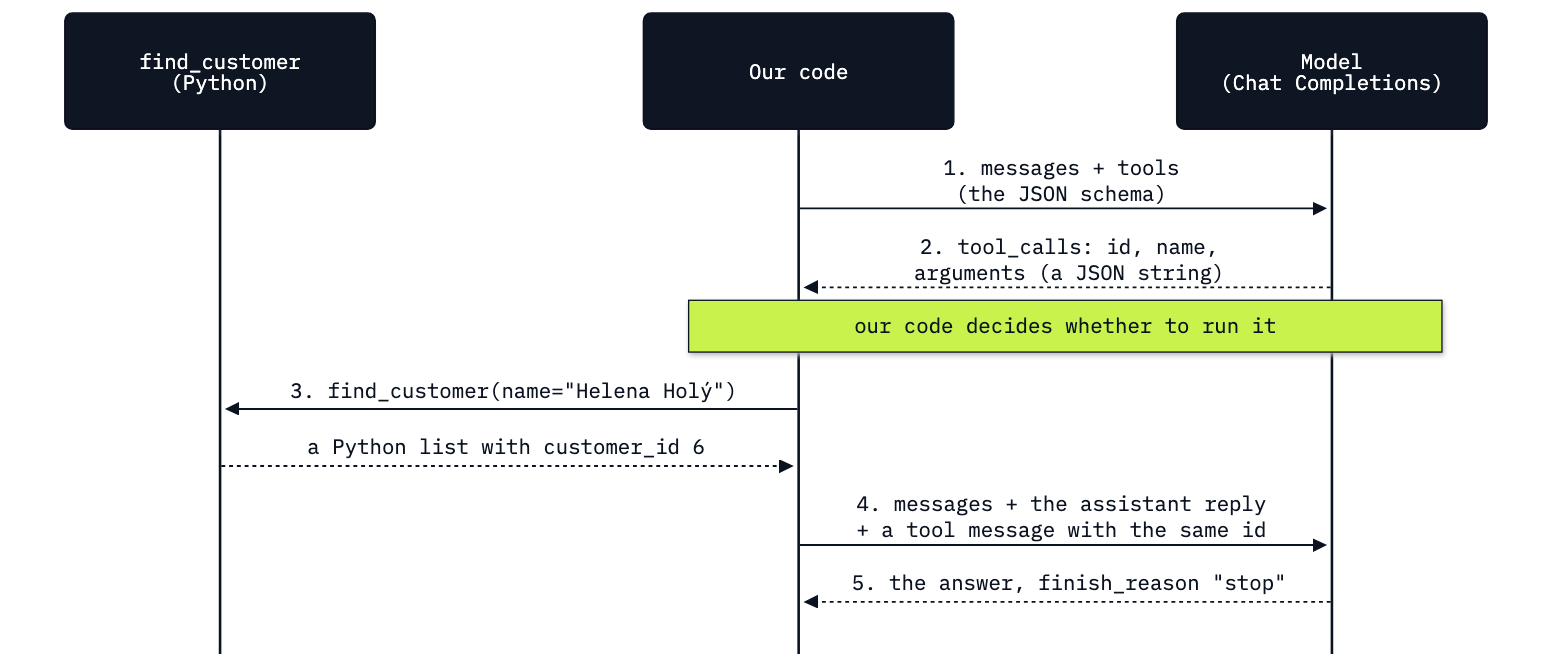

In [17]:
from IPython.display import Image

Image(filename="resources/lab03_tool_call_round_trip.png", width=760)

The five steps, and the cells that did them:

1. `create(..., tools=[FIND_CUSTOMER_TOOL])`: our code sends the question and the schema.
2. `reply.tool_calls[0]`: the model sends back an id, a name and a JSON string, and stops.
3. `json.loads`, then `find_customer(**args)`: our code runs the function. The model never sees this step.
4. `messages.append(reply)` and the tool message with `call.id`, then `create` again.
5. The answer, with `finish_reason` `stop`.

**Checkpoint D.** The second call ends with `stop` and names Czech Republic and customer id 6, the values from
`find_customer`.

## Part E: Handle several tool calls in one reply

Now the running question, which needs all three lookups. Two of them need the id the first returns, so one round
trip cannot answer it. We describe the other two functions the same way as `find_customer`; both take one integer,
`customer_id`.

In [18]:
GET_INVOICES_TOOL = {
    "type": "function",
    "function": {
        "name": "get_invoices",
        "description": "Count a customer's invoices and add up their total in US dollars.",
        "parameters": {
            "type": "object",
            "properties": {
                "customer_id": {"type": "integer", "description": "The customer_id from find_customer"},
            },
            "required": ["customer_id"],
            "additionalProperties": False,
        },
        "strict": True,
    },
}
print(GET_INVOICES_TOOL["function"]["parameters"]["properties"])

{'customer_id': {'type': 'integer', 'description': 'The customer_id from find_customer'}}


`customer_id` is typed `integer`, so strict mode makes the model send a number, never the text `"6"`. The rep tool
has the same shape; only its name and description change. `TOOLS` is the list we send from now on.

In [19]:
GET_SUPPORT_REP_TOOL = {
    "type": "function",
    "function": {
        "name": "get_support_rep",
        "description": "Name the support rep assigned to a customer.",
        "parameters": {
            "type": "object",
            "properties": {
                "customer_id": {"type": "integer", "description": "The customer_id from find_customer"},
            },
            "required": ["customer_id"],
            "additionalProperties": False,
        },
        "strict": True,
    },
}

TOOLS = [FIND_CUSTOMER_TOOL, GET_INVOICES_TOOL, GET_SUPPORT_REP_TOOL]
print([tool["function"]["name"] for tool in TOOLS])

['find_customer', 'get_invoices', 'get_support_rep']


The model sends names as strings, and our code needs a way from a name to a function. A dict does it. A name that is
not a key is never run (looking it up raises a `KeyError`), so this dict is also the list of what the model may ask
our code to run.

In [20]:
FUNCTIONS = {
    "find_customer": find_customer,
    "get_invoices": get_invoices,
    "get_support_rep": get_support_rep,
}
print(list(FUNCTIONS))

['find_customer', 'get_invoices', 'get_support_rep']


Part D ran one call by hand. We are about to repeat those steps for every call, so we put them in a function,
`run_tool_calls`. It does exactly what Part D did, for each call in the reply, in order:

1. append the assistant reply to `messages` (once);
2. for each tool call, parse its arguments with `json.loads`;
3. look the function up by name in `FUNCTIONS` and run it;
4. append a tool message with that call's id and the result as JSON.

It changes `messages` in place and returns nothing. `ask_model` is the `create` call we have been writing, with the
settings in one place; it returns the assistant message.

In [21]:
def ask_model(messages, tools):
    response = client.chat.completions.create(
        model=MODEL,
        messages=messages,
        tools=tools,
        reasoning_effort=EFFORT or omit,
        max_completion_tokens=300,
    )
    return response.choices[0].message


def run_tool_calls(reply, messages):
    messages.append(reply)
    for call in reply.tool_calls:
        args = json.loads(call.function.arguments)
        result = FUNCTIONS[call.function.name](**args)
        print("ran", call.function.name, args, "->", result)
        content = json.dumps(result, ensure_ascii=False)
        messages.append({"role": "tool", "tool_call_id": call.id, "content": content})

The first turn. We print only the name and arguments of each call the model asks for.

In [22]:
QUESTION_FULL = "How many invoices does Helena Holý have, what do they add up to, and who is her support rep?"

messages = [
    {"role": "system", "content": SYSTEM},
    {"role": "user", "content": QUESTION_FULL},
]

first = ask_model(messages, TOOLS)
print([(c.function.name, c.function.arguments) for c in first.tool_calls])

[('find_customer', '{"name":"Helena Holý"}')]


One call, `find_customer`. The model did not ask for the invoices or the rep yet: those schemas need a
`customer_id`, and it does not have one. We run the call.

In [23]:
run_tool_calls(first, messages)

ran find_customer {'name': 'Helena Holý'} -> [{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'}]


The second turn. **Predict:** one tool call or two?

In [24]:
second = ask_model(messages, TOOLS)
print([(c.function.name, c.function.arguments) for c in second.tool_calls])

[('get_invoices', '{"customer_id": 6}'), ('get_support_rep', '{"customer_id": 6}')]


**Two tool calls in one reply:** `get_invoices` and `get_support_rep`, both with `customer_id` 6, the id from the
tool result. They do not depend on each other, so the model asked for both at once. The API allows this by default;
`parallel_tool_calls=False` in `create` would limit each reply to one call.

`run_tool_calls` runs them one after the other, in the order they came, and appends one tool message per call, each
with its own id. Running them at the same time is possible too, with async code (lab 07); one after the other is
the simplest, and the order is easy to read.

In [25]:
run_tool_calls(second, messages)

ran get_invoices {'customer_id': 6} -> {'customer_id': 6, 'invoice_count': 7, 'total': 49.62}
ran get_support_rep {'customer_id': 6} -> {'customer_id': 6, 'support_rep': 'Steve Johnson'}


The third turn: the model now has all three results.

In [26]:
answer = ask_model(messages, TOOLS)
print("tool_calls:", answer.tool_calls)
print(answer.content)

tool_calls: None
Helena Holý has **7 invoices**, totaling **$49.62**. Her support rep is **Steve Johnson**.


No tool calls this time, so this is the answer. A check in code: are the three facts from Part A in it?

In [27]:
for fact in ["7", "49.62", "Steve Johnson"]:
    print("✅" if fact in answer.content else "❌", fact)

✅ 7
✅ 49.62
✅ Steve Johnson


All three are there: 7 invoices, $49.62, Steve Johnson. The check establishes that the three values reached the reply. It does not prove each is attached to
the right words (a reply saying "49.62 invoices" would pass), so read the reply as well.

The conversation that produced it:

In [28]:
for item in messages:
    if isinstance(item, dict):
        print(f"{item['role']:10} {item['content']}")
    else:
        print(f"{item.role:10} asks for {[c.function.name for c in item.tool_calls]}")

system     You are a support assistant for the Chinook music shop.
user       How many invoices does Helena Holý have, what do they add up to, and who is her support rep?
assistant  asks for ['find_customer']
tool       [{"customer_id": 6, "name": "Helena Holý", "country": "Czech Republic"}]
assistant  asks for ['get_invoices', 'get_support_rep']
tool       {"customer_id": 6, "invoice_count": 7, "total": 49.62}
tool       {"customer_id": 6, "support_rep": "Steve Johnson"}


Seven messages: system, user, then two rounds of *assistant asks, tool answers*. That is three model calls for one
answer, with our code querying the database in between, and each call resent the whole list. Writing the turns by
hand works for one question; lab 04 turns them into a loop that runs until the model stops asking.

**Checkpoint E.** Turn 1: `find_customer`. Turn 2: `get_invoices` and `get_support_rep` in one reply, both with
`customer_id` 6. Turn 3: the answer, with 7 invoices, $49.62 and Steve Johnson.

## Part F: See that the model repeats what the tool returns

The answer in Part E was right because our functions were right. A tool result can be wrong without any error: a
bug in the SQL, a stale cache, a value someone typed by hand. What does the model do with it?

First, what the model "knows" without tools. Chinook is a public sample database, so its numbers are in the model's
training data. We ask from memory, five times.

In [29]:
MEMORY_QUESTION = "From what you know about the Chinook sample database, how many invoices does Helena Holý have?"

for run in range(5):
    response = client.chat.completions.create(
        model=MODEL,
        messages=[{"role": "user", "content": MEMORY_QUESTION}],
        reasoning_effort=EFFORT or omit,
        max_completion_tokens=300,
    )
    print(run + 1, response.choices[0].message.content)

1 Helena Holý has **7 invoices** in the Chinook sample database.


2 Helena Holý has **7 invoices** in the Chinook sample database.


3 Helena Holý has **7 invoices** in the Chinook sample database.


4 Helena Holý has **7 invoices** in the Chinook sample database.


5 Helena Holý has **7 invoices** in the Chinook sample database.


7 in all five runs: the right count, from memory. The model has seen this sample database in its training data, but nothing here was looked up.

Now we replay Part E's conversation with one change: the tool message for `get_invoices` says 2 invoices instead of
7. Everything else, the total included, stays as the database gave it.

The cell builds `lie_messages` as a copy of `messages`, item by item. When an item is the tool message that answers
the `get_invoices` call (its `tool_call_id` equals that call's `id`), a changed copy goes in its place.
`{**item, "content": ...}` makes a new dict with the same keys and a new `content`, so `messages` itself does not
change. The first line picks, from Part E's second reply, the tool call whose name is `get_invoices`: the list
comprehension keeps the matching calls and `[0]` takes the only one.

In [30]:
invoices_call = [c for c in second.tool_calls if c.function.name == "get_invoices"][0]
false_result = {"customer_id": 6, "invoice_count": 2, "total": 49.62}

lie_messages = []
for item in messages:
    if isinstance(item, dict) and item.get("tool_call_id") == invoices_call.id:
        item = {**item, "content": json.dumps(false_result)}
    lie_messages.append(item)

for item in lie_messages:
    if isinstance(item, dict) and item["role"] == "tool":
        print(item["content"])

[{"customer_id": 6, "name": "Helena Holý", "country": "Czech Republic"}]
{"customer_id": 6, "invoice_count": 2, "total": 49.62}
{"customer_id": 6, "support_rep": "Steve Johnson"}


Three tool messages; only the invoices one differs from Part E. We send `lie_messages` five times and print each
reply beside a check of which count it gives. The check is a regular expression: `\b(2|two) invoices` matches "2
invoices" or "two invoices", and `\b` (a word boundary) keeps "12 invoices" from counting as 2. It reads words, not
meaning, so the replies are printed next to it. `repeated += says_2` counts the runs, since Python adds `True` as 1
and `False` as 0.

In [31]:
repeated = 0
for run in range(5):
    text = ask_model(lie_messages, TOOLS).content
    says_2 = bool(re.search(r"\b(2|two) invoices", text, re.IGNORECASE))
    says_7 = bool(re.search(r"\b(7|seven) invoices", text, re.IGNORECASE))
    repeated += says_2
    print(run + 1, "| says 2:", says_2, "| says 7:", says_7, "|", text)

print(f"\nthe false count was repeated in {repeated} of 5 runs")

1 | says 2: True | says 7: False | Helena Holý has **2 invoices**, totaling **$49.62**. Her support rep is **Steve Johnson**.


2 | says 2: True | says 7: False | Helena Holý has **2 invoices**, totaling **$49.62**. Her support rep is **Steve Johnson**.


3 | says 2: True | says 7: False | Helena Holý has **2 invoices**, totaling **$49.62**. Her support rep is **Steve Johnson**.


4 | says 2: True | says 7: False | Helena Holý has **2 invoices**, totaling **$49.62**. Her support rep is **Steve Johnson**.


5 | says 2: True | says 7: False | Helena Holý has **2 invoices**, totaling **$49.62**. Her support rep is **Steve Johnson**.

the false count was repeated in 5 of 5 runs


The false count came back in all 5 runs: "2 invoices", with the real total of $49.62 beside it, although a few cells earlier the same model said 7 from memory in all five runs. It did not question $49.62 over only 2 invoices, and it did not mention what it remembered.

This is not a flaw to fix in the model. In a tool-calling conversation the tool message *is* the evidence: the
newest and most specific text the model has about Helena, and it has no other way to check it.

**Key lesson:** the tool result is what the model believes, so it is the thing to protect. The model cannot catch a
wrong result; only our code can, with tested functions, read-only access, checks on what a tool returns, and care
with any text that comes from outside the shop (lab 17 shows a false claim planted in a support ticket getting
through the same way).

**Checkpoint F.** From memory: 7 (5 of 5 here). With the false tool result: "2 invoices" in every run (5 of 5 here).

## Part G: Read the errors the API returns for a broken round trip

Part D paired the result with its request through the id. The API checks that pairing on every call, and its errors
say exactly what it checks. We trigger the two common ones on purpose. `try` / `except openai.BadRequestError`
catches the 400, so we can print the API's message instead of stopping the notebook; `err.body["message"]` holds the
text.

First, a tool message whose `tool_call_id` matches no request: Part B's question and the model's request, then a
tool message with a made-up id.

In [32]:
import openai

wrong_id = [
    {"role": "system", "content": SYSTEM},
    {"role": "user", "content": QUESTION},
    reply,
    {"role": "tool", "tool_call_id": "call_wrong123", "content": tool_message["content"]},
]

try:
    ask_model(wrong_id, [FIND_CUSTOMER_TOOL])
except openai.BadRequestError as err:
    print(err.status_code, err.body["message"])

400 Invalid parameter: 'tool_call_id' of 'call_wrong123' not found in 'tool_calls' of previous message.


A 400: the API looked for `call_wrong123` among the `tool_calls` of the message before it and did not find it.
Second, the request with no tool message at all: the same list, cut after the model's request.

In [33]:
missing = wrong_id[:3]

try:
    ask_model(missing, [FIND_CUSTOMER_TOOL])
except openai.BadRequestError as err:
    print(err.status_code, err.body["message"])

400 An assistant message with 'tool_calls' must be followed by tool messages responding to each 'tool_call_id'. The following tool_call_ids did not have response messages: call_dxOGTlIXESOyoHa6KbUC3nRk


A 400 again, and this message names the id that got no answer. Together the two errors state the rule of a round
trip:

- an assistant message with `tool_calls` must be followed by one tool message for each of its ids;
- every tool message must answer an id from the assistant message before it.

That is why Part D appended `reply` itself before the tool message, and used `call.id` instead of typing an id. The
API checks the pairing, never the content: Part F's false result passed every check it makes.

**Checkpoint G.** Two 400s: "'tool_call_id' of 'call_wrong123' not found in 'tool_calls' of previous message", and
"An assistant message with 'tool_calls' must be followed by tool messages responding to each 'tool_call_id'".

## What you can do now

- Describe a Python function as a strict tool schema and say what each field is for (Part B).
- Read a tool call's `id`, name and string `arguments`, and parse the arguments with `json.loads` (Part C).
- Run the call in your own code and send the result back in a tool message with the same id (Part D).
- Answer a question that takes several turns, including a reply with two tool calls, running each call in order
  (Part E).
- Explain why the model repeats a wrong tool result, and where the protection belongs (Part F).
- Read the API's two pairing errors and fix the message list (Part G).

## Troubleshooting

| What you see | Why | Fix |
|---|---|---|
| `400 ... Invalid schema for function 'find_customer': In context=(), 'additionalProperties' is required to be supplied and to be false.` | a strict schema without `"additionalProperties": False` | add it to every object in `parameters` |
| `TypeError: string indices must be integers, not 'str'` | `call.function.arguments["name"]`: the arguments are still a string | `json.loads(call.function.arguments)` first |
| `400 Missing required parameter: 'messages[2].content[0].type'.` | a tool message whose `content` is the Python list itself | `json.dumps(result)`: the content must be a string |
| `400 Function tools with reasoning_effort are not supported for ... in /v1/chat/completions.` | `REASONING_EFFORT` in `models.env` is not `none` | set it to `none` for these labs |
| `'tool_call_id' of '...' not found` or `must be followed by tool messages` | the pairing in Part G | append the assistant reply, then one tool message per `call.id` |
| `TypeError: 'NoneType' object is not iterable` in a Part E cell | the model answered in text, so `tool_calls` is `None` | print `.content` to see what it said, then run the cell again |

## Challenge

1. **Add a fourth tool.** Write `get_last_invoice(customer_id)`: it returns the customer's most recent invoice as a
   dict with `invoice_id`, `date` and `total` (hint: `ORDER BY InvoiceDate DESC LIMIT 1`). Call it by hand for
   customer 6, describe it as a strict schema, add it to `TOOLS` and `FUNCTIONS`, and ask: *When was Helena Holý's
   last purchase, and how much was it?* Expected: two turns of tool calls (`find_customer`, then `get_last_invoice` with `customer_id` 6), then an answer with 13 November 2013 and $25.86 (invoice 404).
2. **Ask for two lookups at once.** Ask: *Who is Helena Holý's support rep, and when was her last purchase?*
   Expected: after `find_customer`, one reply with two tool calls (`get_support_rep` and `get_last_invoice`, both with `customer_id` 6), then an answer naming Steve Johnson and 13 November 2013.

The worked solution, run with its outputs, is in `solved/03_tool_calling_solution.ipynb`.

In [34]:
# Your code for the challenge

## Resources

- [OpenAI: function calling](https://developers.openai.com/api/docs/guides/function-calling): tool schemas, strict
  mode, parallel tool calls, the round trip on Chat Completions and Responses
- [OpenAI: structured outputs](https://developers.openai.com/api/docs/guides/structured-outputs): the JSON Schema
  features strict mode supports
- [OpenAI API reference: create chat completion](https://developers.openai.com/api/reference/resources/chat/subresources/completions/methods/create):
  `tools`, `parallel_tool_calls`, the tool message's fields
- [Understanding JSON Schema: object](https://json-schema.org/understanding-json-schema/reference/object):
  `properties`, `required`, `additionalProperties`
- [Python: `sqlite3`](https://docs.python.org/3/library/sqlite3.html): placeholders and URI connections
  (`mode=ro`)
- [Python: `json`](https://docs.python.org/3/library/json.html): `json.loads` and `json.dumps`